In [10]:
import moabb
from moabb.datasets import BNCI2014_001
from moabb.evaluations import WithinSessionEvaluation
from moabb.paradigms import MotorImagery, FilterBankMotorImagery
from moabb.pipelines.features import AugmentedDataset
from moabb.pipelines.utils import FilterBank

from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import GridSearchCV

from pyriemann.spatialfilters import CSP
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

import pandas as pd
import numpy as np

from datetime import datetime


In [11]:
import mne, sklearn, pyriemann

print("MOABB:", moabb.__version__)
print("MNE:", mne.__version__)
print("scikit-learn:", sklearn.__version__)
print("pyRiemann:", pyriemann.__version__)

MOABB: 1.7.1
MNE: 1.12.1
scikit-learn: 1.9.0
pyRiemann: 0.12


In [12]:
from pathlib import Path

RESULTS_PATH = Path( "moabb_reproduce_rerun" )
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

In [13]:
# ignore some warnings
import warnings
from h5py.h5py_warnings import H5pyDeprecationWarning

warnings.filterwarnings( "ignore", message=r"Montage name 'standard_1005' is deprecated.*", category=FutureWarning )
warnings.filterwarnings( "ignore", message=r"Creating a dataset without passing data or dtype is deprecated.*", category=H5pyDeprecationWarning )
warnings.filterwarnings( "ignore", message=r"`optuna\.terminator` module has been deprecated.*", category=FutureWarning )

# Воспроизводятся результаты для двух пайпланов ACM+TS+SVM и FBCSB+SVM из https://arxiv.org/html/2404.15319v1

Датасет: BNCI 2014 001.

Воспроизводится Within-session для 4 классов.


Похоже, что в коде MOABB сейчас есть ошибка, из-за которой при использовании FilterBankMotorImagery в дальнешую обработку передаются не все FB полосы, а только первая.
* https://github.com/NeuroTechX/moabb/blob/v1.7.2/moabb/evaluations/base.py#L1080-L1085 - берется первое значение [0]
* https://github.com/NeuroTechX/moabb/pull/774/changes#diff-bc7c12c88946582600153a3aa78e7347ee014955fa041caaa4eb96fbdcfc2ce7R164 - передается в get_data

В версии 1.0.0, по которой написана статья, этой проблемы еще не было.
Попробовала исправить это (FilterBankMotorImageryFix), стандартный вариант на всякий случай тоже оставила для сравнения, но видно, что результаты там получились хуже.



In [14]:
dataset = BNCI2014_001()
#dataset.subject_list = [1]

paradigm = MotorImagery( n_classes=4, fmin=8, fmax=32 ) # 8, 32 are default values

fb_filters = ( [8, 12], [12, 16], [16, 20], [20, 24], [24, 28], [28, 32] ) # standard moabb values

paradigm_fb = FilterBankMotorImagery( n_classes=4, filters=fb_filters )

# looks like there is an error in moabb and only first band is used
# trying to fix it with process_pipelines=None
class FilterBankMotorImageryFix(FilterBankMotorImagery):
    def get_data(self, dataset, *args, process_pipelines=None, **kwargs):
        return super().get_data(
            dataset,
            *args,
            process_pipelines=None,
            **kwargs,
        )

paradigm_fix = FilterBankMotorImageryFix( n_classes=4, filters=fb_filters )

2026-10-11 19:41:23,072 WARNING MainThread moabb.paradigms.motor_imagery Choosing from all possible events
2026-10-11 19:41:23,072 WARNING MainThread moabb.paradigms.motor_imagery Choosing from all possible events
2026-10-11 19:41:23,073 WARNING MainThread moabb.paradigms.motor_imagery Choosing from all possible events


# Параметры из статьи (Table 5): 
* ACM+TS+SVM:
  * augmenteddataset_order: [1 - 10]
  * augmenteddataset_lag: [1 - 10]
  * svc_C: [0.5, 1, 1.5]
  * svc_kernel: [”rbf”, ”linear”]
* FBCSP+SVM - не указаны
  * Есть параметры для CSP+SVM
    * csp_nfilter: [2 - 8]
    * svc_C: [0.5, 1, 1.5]
    * svc_kernel: [”rbf”, ”linear”]
  * И параметры из кода https://github.com/NeuroTechX/moabb/blob/develop/pipelines/FBCSP.py
    * csp_nfilter: 4
    * svc_C: np.logspace(-2, 2, 10)
    * svc_kernel: ”linear”
  * Были проверены оба варианта

Вместо полного перебора параметров использовалась optuna для ускорения.


In [15]:
moabb.set_log_level(level='INFO')

N_JOBS = 1 
RS = 42

acm_name = "ACM+TS+SVM"
acm_ts_svm = make_pipeline(
        AugmentedDataset(),
        Covariances(estimator="cov"),
        TangentSpace(metric="riemann"),
        SVC(),
    )

acm_param = {
        "augmenteddataset__order": list(range(1, 11)),
        "augmenteddataset__lag": list(range(1, 11)),
        "svc__C": [0.5, 1.0, 1.5],
        "svc__kernel": ["linear", "rbf"],
}

fbcsp_name = "FBCSP+SVM (error)"
fbcspfix_name = "FBCSP+SVM (csp_svm params)"
fbcsp_p2_name = "FBCSP+SVM (code params)"
fbcsp_svm = make_pipeline(
        FilterBank( make_pipeline ( Covariances(estimator="oas"), CSP() ) ),
        SelectKBest(score_func=mutual_info_classif, k=10),
        SVC(),
    )

fbcsp_param = { 
    "filterbank__estimator__csp__nfilter": list(range(2, 9)),
    "svc__C": [0.5, 1.0, 1.5],
    "svc__kernel": ["rbf", "linear"],
 }

fbcsp_svm2 = make_pipeline(
        FilterBank( make_pipeline ( Covariances(estimator="oas"), CSP(nfilter=4) ) ),
        SelectKBest( score_func=mutual_info_classif, k=10 ),
        GridSearchCV( SVC(kernel="linear"), { "C": np.logspace(-2, 2, 10) } ),
    )

results = {}
params = dict( datasets=[dataset], random_state=RS, save_model=True, optuna=True, n_jobs=N_JOBS, hdf5_path=str(RESULTS_PATH) )

print( f"{datetime.now().strftime( '%H:%M:%S')} Running {acm_name}..." )
evaluation =  WithinSessionEvaluation( paradigm=paradigm, overwrite=False,  **params )
res =  evaluation.process( { acm_name: acm_ts_svm }, param_grid={ acm_name: acm_param } )

print( f"{datetime.now().strftime('%H:%M:%S')} Running {fbcsp_name}..." )
evaluation_fb = WithinSessionEvaluation( paradigm=paradigm_fb,  overwrite=False,  **params )
res_fb =  evaluation_fb.process( { fbcsp_name: fbcsp_svm }, param_grid={ fbcsp_name: fbcsp_param } )

print( f"{datetime.now().strftime('%H:%M:%S')} Running {fbcspfix_name}..." )
evaluation_fix = WithinSessionEvaluation( paradigm=paradigm_fix, overwrite=False,  **params )
res_fix = evaluation_fix.process( { fbcspfix_name: fbcsp_svm }, param_grid={ fbcspfix_name: fbcsp_param } )

print( f"{datetime.now().strftime('%H:%M:%S')} Running {fbcsp_p2_name}..." )
evaluation_p2 = WithinSessionEvaluation( paradigm=paradigm_fix, overwrite=False, suffix="_p2",  **params )
res_p2 = evaluation_p2.process(   { fbcsp_p2_name: fbcsp_svm2 } )


results = pd.concat([res, res_fb, res_fix, res_p2 ])
print( f"{datetime.now().strftime('%H:%M:%S')} Done!" )


19:41:23 Running ACM+TS+SVM...


[I 2026-10-11 19:41:33,637] A new study created in memory with name: no-name-8373c9a1-1663-402c-9282-e1ac6550fe87
[I 2026-10-11 19:41:38,062] Trial 0 finished with value: 0.856516290726817 and parameters: {'augmenteddataset__order': 5, 'augmenteddataset__lag': 10, 'svc__C': 1.0, 'svc__kernel': 'rbf'}. Best is trial 0 with value: 0.856516290726817.
[I 2026-10-11 19:41:40,209] Trial 1 finished with value: 0.8738323080428344 and parameters: {'augmenteddataset__order': 3, 'augmenteddataset__lag': 4, 'svc__C': 1.0, 'svc__kernel': 'rbf'}. Best is trial 1 with value: 0.8738323080428344.
[I 2026-10-11 19:41:45,262] Trial 2 finished with value: 0.8609022556390977 and parameters: {'augmenteddataset__order': 5, 'augmenteddataset__lag': 6, 'svc__C': 1.0, 'svc__kernel': 'rbf'}. Best is trial 1 with value: 0.8738323080428344.
[I 2026-10-11 19:42:05,574] Trial 3 finished with value: 0.8913192071086807 and parameters: {'augmenteddataset__order': 8, 'augmenteddataset__lag': 5, 'svc__C': 0.5, 'svc__kern

22:51:02 Running FBCSP+SVM (error)...


[I 2026-10-11 22:51:13,251] A new study created in memory with name: no-name-38f92a20-d5bb-482f-b876-4743b1cf6c73
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10 is greater than n_features=4. All the features will be returned.
  warnings.warn(
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10 is greater than n_features=4. All the features will be returned.
  warnings.warn(
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/sklearn/feature_selection/_univariate_selection.py:782: UserWarning: k=10 is greater than n_features=4. All the features will be returned.
  warnings.warn(
[I 2026-10-11 22:51:14,039] Trial 0 finished with value: 0.6822738664843927 and parameters: {'filterbank__estimator__csp__nfilter': 4, 'svc__C': 1.5, 'svc__kernel': 'linear'}. Best is trial 0 with

23:02:23 Running FBCSP+SVM (csp_svm params)...


[I 2026-10-11 23:03:31,448] A new study created in memory with name: no-name-d6288def-aabf-4df2-9669-4de9c0f40d0f
[I 2026-10-11 23:03:35,477] Trial 0 finished with value: 0.6564137616769196 and parameters: {'filterbank__estimator__csp__nfilter': 2, 'svc__C': 1.0, 'svc__kernel': 'rbf'}. Best is trial 0 with value: 0.6564137616769196.
[I 2026-10-11 23:03:39,979] Trial 1 finished with value: 0.7392344497607656 and parameters: {'filterbank__estimator__csp__nfilter': 7, 'svc__C': 1.5, 'svc__kernel': 'rbf'}. Best is trial 1 with value: 0.7392344497607656.
[I 2026-10-11 23:03:44,255] Trial 2 finished with value: 0.64792663476874 and parameters: {'filterbank__estimator__csp__nfilter': 3, 'svc__C': 1.5, 'svc__kernel': 'linear'}. Best is trial 1 with value: 0.7392344497607656.
[I 2026-10-11 23:03:48,259] Trial 3 finished with value: 0.6258828890407838 and parameters: {'filterbank__estimator__csp__nfilter': 2, 'svc__C': 1.0, 'svc__kernel': 'linear'}. Best is trial 1 with value: 0.7392344497607656

00:07:01 Running FBCSP+SVM (code params)...


2026-10-12 00:10:15,765 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 8 | 1test: Score 0.697
2026-10-12 00:10:15,768 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 8 | 0train: Score 0.757
2026-10-12 00:10:15,768 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 2 | 1test: Score 0.545
2026-10-12 00:10:15,768 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 2 | 0train: Score 0.566
2026-10-12 00:10:15,768 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 6 | 1test: Score 0.445
2026-10-12 00:10:15,769 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 6 | 0train: Score 0.506
2026-10-12 00:10:15,769 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 1 | 1test: Score 0.768
2026-10-12 00:10:15,769 INFO MainThread moabb.evaluations.base FBCSP+SVM (code params) | BNCI2014-001 | 1 | 

00:10:15 Done!


# Результаты из статьи и на сайте MOABB для сравнения
* ACM+TS+SVM: 77.82±12.23
* FilterBank+SVM: 66.53±12.05 

In [16]:
print( results.groupby("pipeline")["score"].agg(["mean", "std"]) )
#print(results.groupby("pipeline")["time"].sum())

                                mean       std
pipeline                                      
ACM+TS+SVM                  0.765467  0.135772
FBCSP+SVM (code params)     0.662795  0.127462
FBCSP+SVM (csp_svm params)  0.678662  0.143517
FBCSP+SVM (error)           0.569023  0.180694


2026-10-12 00:10:15,814 WARNING MainThread moabb.analysis.plotting Dataset names are too similar, turning off name shortening
/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/moabb/analysis/plotting.py:434: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  sea.stripplot(


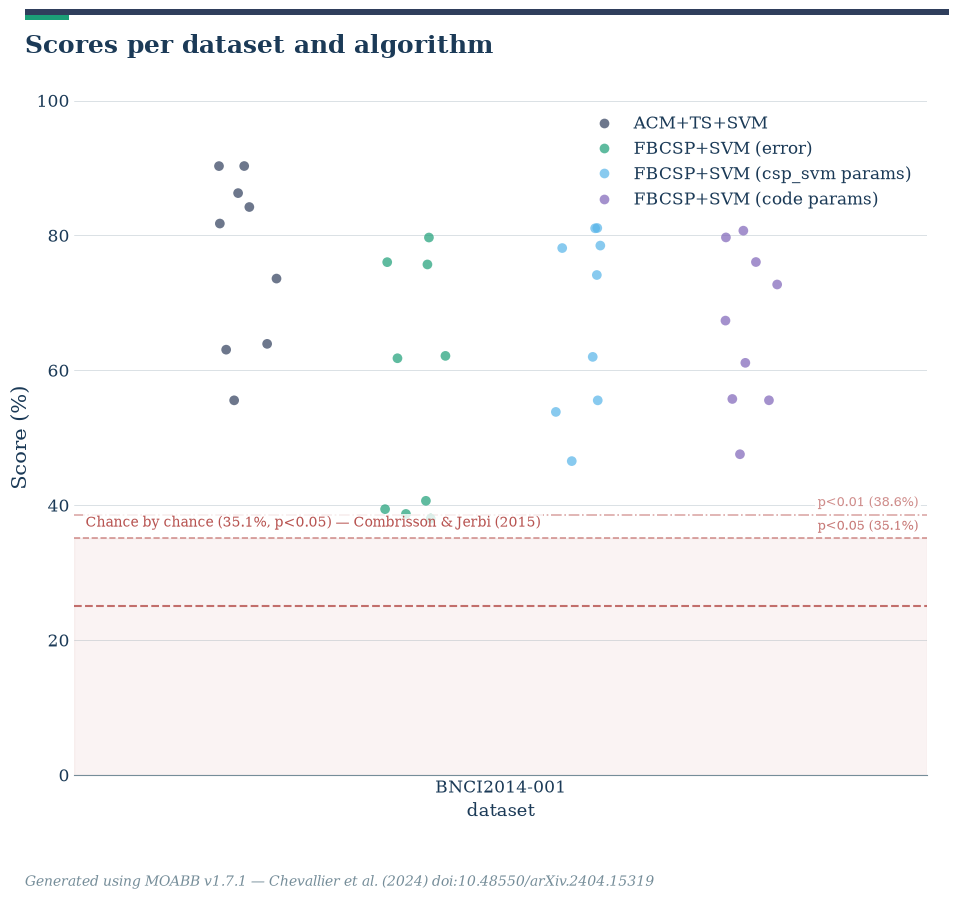

In [17]:
import matplotlib.pyplot as plt

from moabb.analysis.chance_level import chance_by_chance
from moabb.analysis.plotting import score_plot

chance_levels = chance_by_chance(results, alpha=[0.05, 0.01])

fig, _ = score_plot(results, chance_level=chance_levels)

plt.show()

In [18]:
pd.set_option("display.max_rows", None)
display( results[["pipeline", "subject", "session", "score", "time"]] )

,pipeline,subject,session,score,time
0,ACM+TS+SVM,8,1test,0.906171,124.562233
1,ACM+TS+SVM,8,0train,0.899516,100.629486
2,ACM+TS+SVM,2,1test,0.653176,114.270683
3,ACM+TS+SVM,2,0train,0.625227,133.068970
4,ACM+TS+SVM,6,1test,0.548215,106.066605
5,ACM+TS+SVM,6,0train,0.562734,118.218758
6,ACM+TS+SVM,1,1test,0.840593,85.750526
7,ACM+TS+SVM,1,0train,0.843557,150.682510
8,ACM+TS+SVM,9,0train,0.708288,168.009766
9,ACM+TS+SVM,9,1test,0.926860,145.017487
